In [63]:
%reload_ext autoreload
%autoreload 2

import os
import sys
sys.path.append('../')
from pathlib import Path
import re
import numpy as np
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt

# my inference model modules
from latentEnthalpyModel import BasalEvidence, PosteriorConfig
from Simulation import Simulation
from lowRankGPPrior import lowRankGPPrior
from GMMPrior import GMMPrior
from posteriorObjective import posteriorObjective

# Part 1: Load data

Here we load the simulation data, grid, basal thermal evidence (as masks), and create the extent list for visualizing 2D data

In [2]:
data_path = "../data/"

# load simulations, grid, evidence masks, and pressure melting point
grid          = np.load(data_path + "grid.npz")
simulations   = np.load(data_path + "simulations.npz")
evidence_mask = np.load(data_path + "evidence_masks.npz")
pmp           = np.load(data_path + "pmp.npz")["pmp"]

# grid extent
extent_m  = [grid["x"].min(), grid["x"].max(), grid["y"].min(), grid["y"].max()]
extent_km = [x / 1e3 for x in extent_m]

# Part 2: standardization of simulation data

Show the min, max, and the max-min difference diagnostic

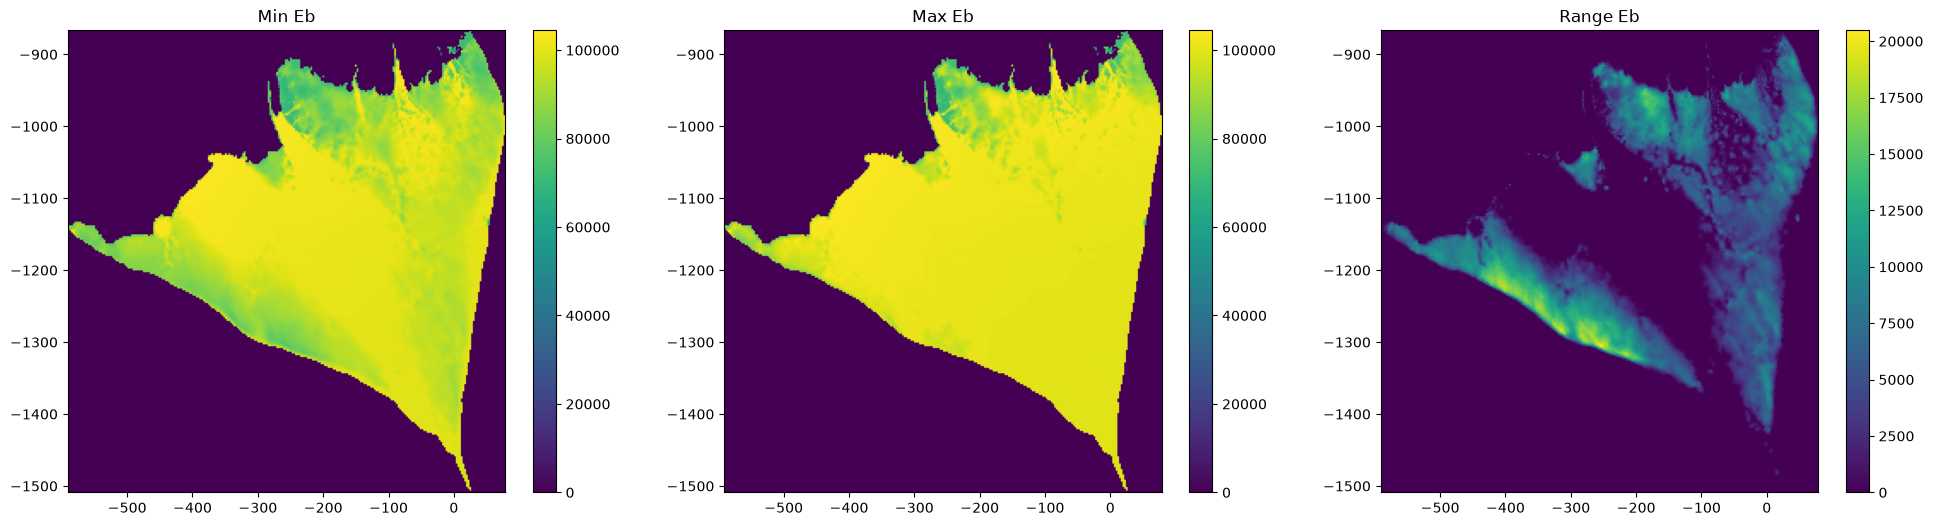

In [3]:
# show the min and max of simulation Eb
min_Eb = np.min(simulations["Eb"], axis = 0)
max_Eb = np.max(simulations["Eb"], axis = 0)

plt.figure(figsize=(24, 6))
plt.subplot(1, 3, 1)
plt.imshow(min_Eb, aspect='auto', origin='lower', extent=extent_km)
plt.title("Min Eb")
plt.colorbar()

plt.subplot(1, 3, 2)
plt.imshow(max_Eb, aspect='auto', origin='lower', extent=extent_km)
plt.title("Max Eb")
plt.colorbar()

plt.subplot(1, 3, 3)
plt.imshow(max_Eb - min_Eb, aspect='auto', origin='lower', extent=extent_km)
plt.title("Range Eb")
plt.colorbar()

plt.show()

/home/donglaiyang/Documents/Georgia-Tech/Research/GMR-inference/src/Simulation.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


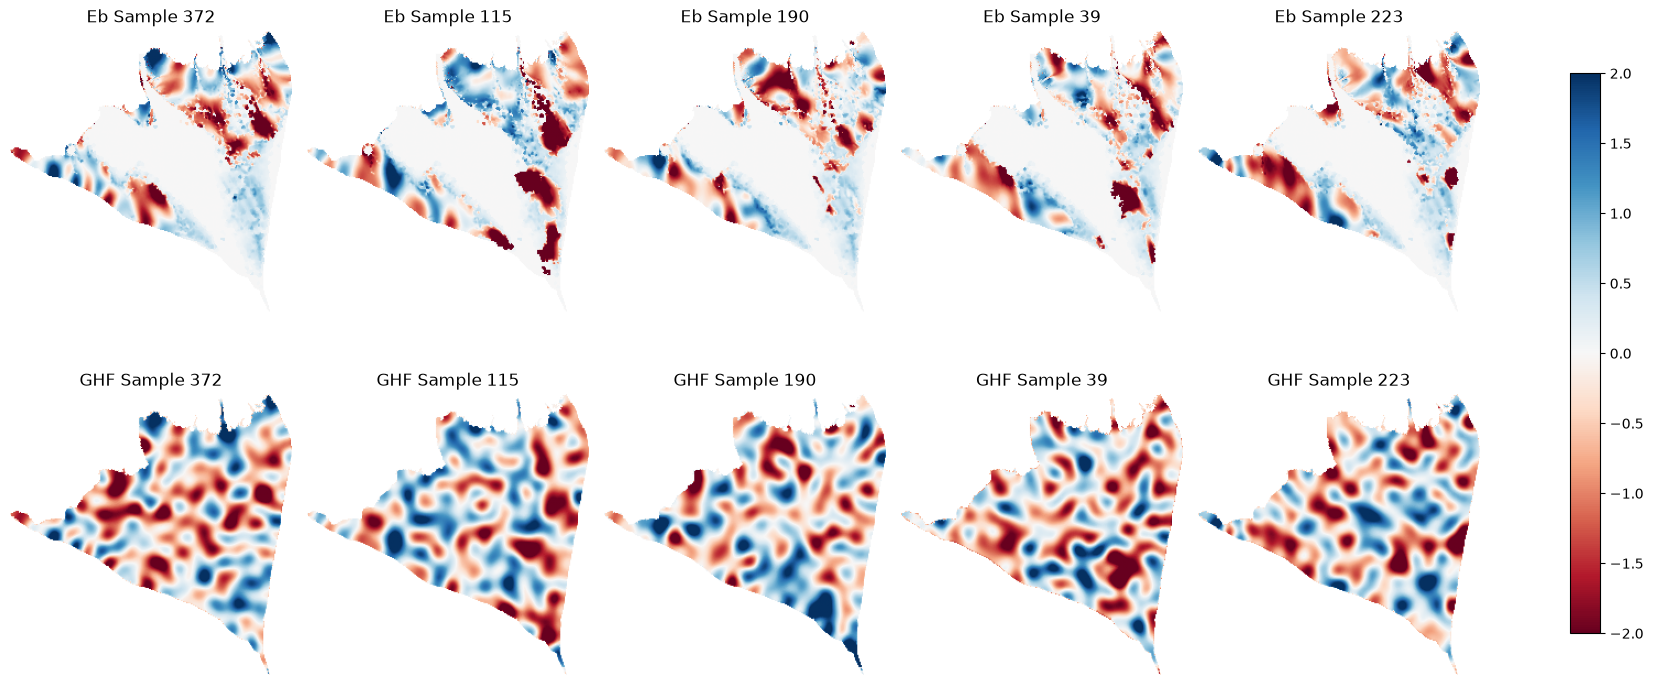

In [4]:
sims = Simulation(
    extent = extent_m,
    coord  = [grid["x"], grid["y"]]
)

sims.load_sim_data(
    X = [simulations["Eb"], simulations["GHF"]],
    labels = ["Eb", "GHF"],
    domain_mask = grid["mask"]
)

sims.show_data(n_samples_to_plot=5)


# Part 3: Density estimation on reduced-dimension simulation data

Find latent representation and tranformation via PAC and apply Gaussian Mixture Model 

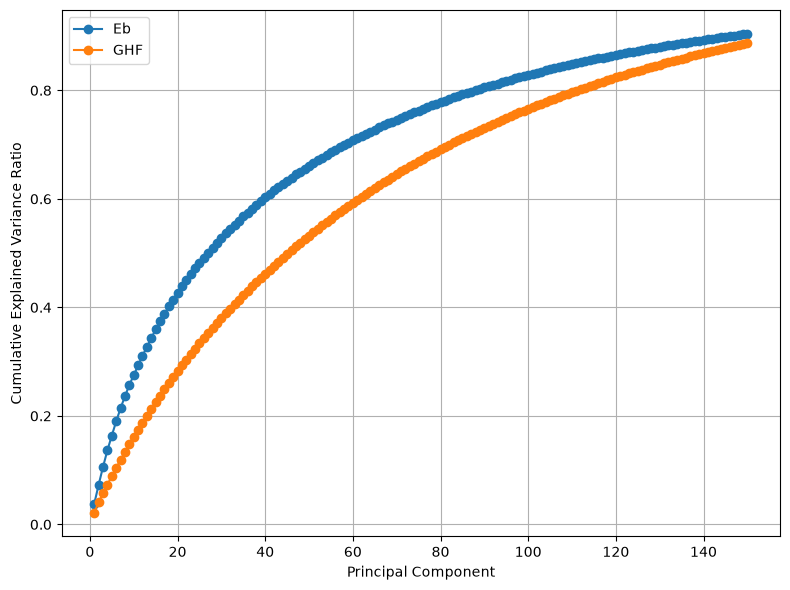

In [5]:
latent_spaces = [150, 150]

sims.find_reduction_model_pca(
    n_latent = latent_spaces,
    show_scree=True)

In [6]:
# split the data into training, validation, and test sets
sims.split_data(train_ratio=0.8, validation_ratio=0.1, test_ratio=0.1)

gmm_n_gaussians = [3, 3]
sims.gmm_prior(n_gaussians = gmm_n_gaussians)

Splitting data: Total samples = 500
-------- Field 0: 
    Shape of X_train[0]: (400, 150)
    Shape of X_validation[0]: (50, 150)
    Shape of X_test[0]: (50, 150)
-------- Field 1: 
    Shape of X_train[1]: (400, 150)
    Shape of X_validation[1]: (50, 150)
    Shape of X_test[1]: (50, 150)
-----------------------------
-----------------------------
Fitting GMMs for each field
--------- Field 0, number of Gaussians: 3
--------- Field 1, number of Gaussians: 3


# Part 4: Creating a mixed prior, likelihood

Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


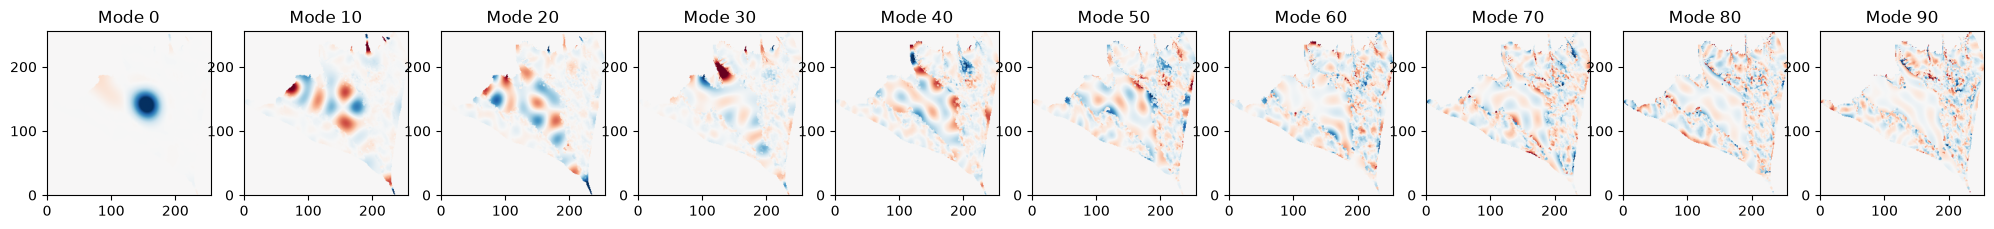

In [51]:
# prior distributions
gp_prior = lowRankGPPrior(
    domain_mask = sims.domain_mask,
    hx = sims.delta_x,
    hy = sims.delta_y,
    n_mode = 100,
    pca_basis = sims.pca_x[0].components_.T, # only look at Eb
    sigma_amp = 50,
    nu = 1,
    rho = 1, # 1
)

sim_prior = GMMPrior(
    gmm = sims.gmms[0]
)

gp_prior.plot_discrepancy_modes()


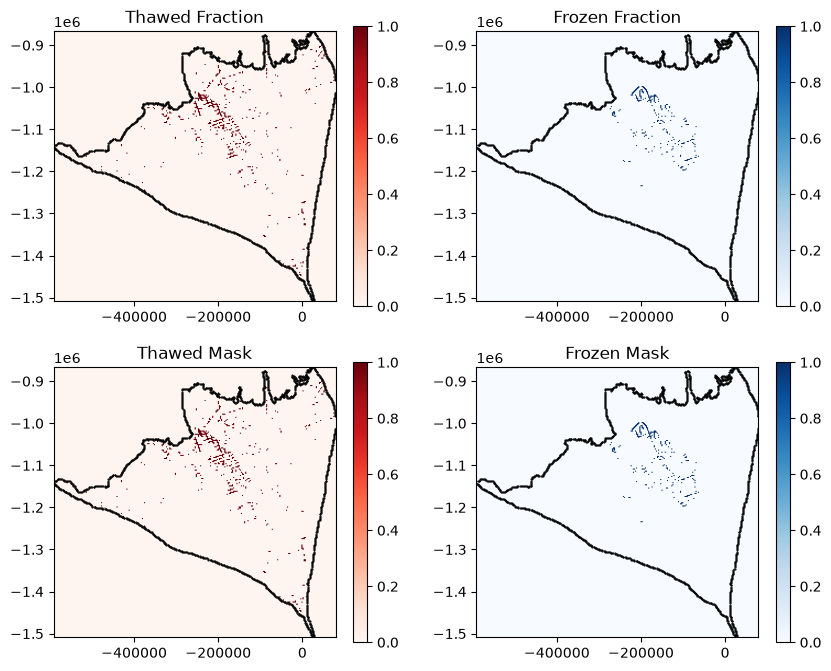

In [52]:
# remove pixels that are in conflict
thawed_mask = evidence_mask["thawed_mask"] & ~evidence_mask["conflict_mask"]
frozen_mask = evidence_mask["frozen_mask"] & ~evidence_mask["conflict_mask"]
thawed_frac_area = np.where(thawed_mask, 1, 0)
frozen_frac_area = np.where(frozen_mask, 1, 0)

# likelihood
evidence = BasalEvidence.from_arrays(
    Tpmp = pmp,
    thawed_mask = thawed_mask,
    frozen_mask = frozen_mask,
    dw = thawed_frac_area,
    df = frozen_frac_area,
)

# visualize the basal evidence
# plot the data
plt.figure(figsize=(10,8))
plt.subplot(2,2,1)
plt.imshow(evidence.thawed_fraction.reshape(sims.nx, sims.ny), 
           cmap='Reds', origin="lower", extent=sims.extent)
for x,y in sims.domain_bound_line:
    plt.plot(x, y, 'k.', markersize=1)
plt.title("Thawed Fraction")
plt.colorbar()
plt.subplot(2,2,2)
plt.imshow(evidence.frozen_fraction.reshape(sims.nx, sims.ny), 
           cmap='Blues', 
           origin="lower", extent=sims.extent)
for x,y in sims.domain_bound_line:
    plt.plot(x, y, 'k.', markersize=1)
plt.title("Frozen Fraction")
plt.colorbar()
plt.subplot(2,2,3)
plt.imshow(evidence.thawed_mask.reshape(sims.nx, sims.ny), 
           cmap='Reds', origin="lower", extent=sims.extent)
for x,y in sims.domain_bound_line:
    plt.plot(x, y, 'k.', markersize=1)
plt.title("Thawed Mask")
plt.colorbar()
plt.subplot(2,2,4)
plt.imshow(evidence.frozen_mask.reshape(sims.nx, sims.ny), 
           cmap='Blues', origin="lower", extent=sims.extent)
for x,y in sims.domain_bound_line:
    plt.plot(x, y, 'k.', markersize=1)
plt.title("Frozen Mask")
plt.colorbar()
plt.show()

config = PosteriorConfig(
    beta = 0.5,
    beta_w = 0.005
)

# Part 5 (A): Solve for MAP with GMM-only model

In [ ]:
import torch
import scipy as sp
import itertools

from latentEnthalpyModel import latentEnthalpyModelGMMOnly
from enthalpyPosterior import enthalpyPosteriorGMMOnly
from posteriorObjective import PosteriorObjectiveGMMOnly

iteration_counter = itertools.count(1)

def print_progress(intermediate_result):
    iteration = next(iteration_counter)

    # SciPy supplies the current parameters and objective value.
    theta = intermediate_result.x
    value = intermediate_result.fun

    # Additional gradient evaluation for monitoring.
    gradient = np.asarray(objective.gradient(theta))
    grad_inf = np.max(np.abs(gradient))

    print(
        f"{iteration:4d} | "
        f"objective = {value: .8e} | "
        f"||grad||_inf = {grad_inf:.3e}",
        flush=True,
    )



forward_model = latentEnthalpyModelGMMOnly(
    pca = sims.pca_x[0],
    scaler = sims.scaling_models[0],
    Tpmp = pmp,
)

posterior = enthalpyPosteriorGMMOnly(
    forward_model = forward_model,
    evidence = evidence,
    gmm = sim_prior,
    config = config,
)

# initialize posterior guess
n_gmm_dim = sims.ndim_reduced[0]

objective = PosteriorObjectiveGMMOnly(
    posterior = posterior,
)


theta0 = torch.zeros(n_gmm_dim)

print("Iter | Objective value | Gradient infinity norm")

result = sp.optimize.minimize(
    fun=objective.value,
    x0=theta0,
    jac=objective.gradient,
    method="L-BFGS-B",
    callback=print_progress,
    options={
        "maxiter": 200,
        "maxfun": 3000,
        "maxls": 30,
        "ftol": 1e-9,
        "gtol": 1e-6,
    },
)

Iter | Objective value | Gradient infinity norm
   1 | objective =  3.33197333e+03 | ||grad||_inf = 1.645e+00
   2 | objective =  3.14117805e+03 | ||grad||_inf = 1.935e+00
   3 | objective =  3.07239828e+03 | ||grad||_inf = 2.669e+00
   4 | objective =  2.97140392e+03 | ||grad||_inf = 1.098e+00
   5 | objective =  2.94115037e+03 | ||grad||_inf = 6.777e-01
   6 | objective =  2.89208383e+03 | ||grad||_inf = 7.730e-01
   7 | objective =  2.83873385e+03 | ||grad||_inf = 9.832e-01
   8 | objective =  2.82559407e+03 | ||grad||_inf = 1.046e+00
   9 | objective =  2.80678390e+03 | ||grad||_inf = 4.196e-01
  10 | objective =  2.78902420e+03 | ||grad||_inf = 4.830e-01
  11 | objective =  2.77519996e+03 | ||grad||_inf = 5.235e-01
  12 | objective =  2.76889741e+03 | ||grad||_inf = 9.296e-01
  13 | objective =  2.75004131e+03 | ||grad||_inf = 1.051e+00
  14 | objective =  2.74866221e+03 | ||grad||_inf = 6.413e-01
  15 | objective =  2.74344350e+03 | ||grad||_inf = 4.264e-01
  16 | objective =  2.

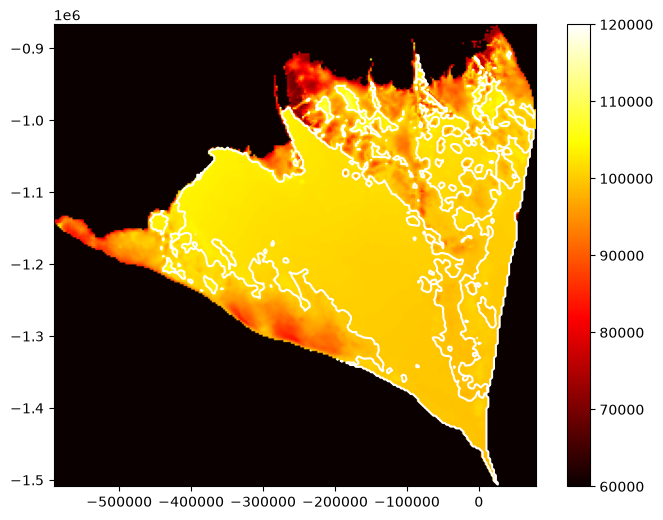

In [68]:
# MAP
map_z_gmm = result.x
enthalpy_map = forward_model.enthalpy(map_z_gmm)
physical_result_MAP = forward_model.physical_state(map_z_gmm)

plt.figure(figsize=(8, 6))
plt.imshow(enthalpy_map.reshape(sims.nx, sims.ny),
           cmap='hot',
           origin='lower',
           vmin=6e4, vmax=12e4,
           extent=sims.extent)
plt.colorbar()

# add a 0.5 contour
plt.contour(physical_result_MAP["delta_T"].reshape(sims.nx, sims.ny),
            levels=[0.1],
            colors='white',
            extent=sims.extent)
plt.show()


# Part 5(B): Solve for MAP with GP-Only prior

In [88]:
import torch
import scipy as sp
import itertools

from latentEnthalpyModel import latentEnthalpyModelGPOnly
from enthalpyPosterior import enthalpyPosteriorGPOnly
from posteriorObjective import PosteriorObjectiveGPOnly

iteration_counter = itertools.count(1)

def print_progress(intermediate_result):
    iteration = next(iteration_counter)

    # SciPy supplies the current parameters and objective value.
    theta = intermediate_result.x
    value = intermediate_result.fun

    # Additional gradient evaluation for monitoring.
    gradient = np.asarray(objective.gradient(theta))
    grad_inf = np.max(np.abs(gradient))

    print(
        f"{iteration:4d} | "
        f"objective = {value: .8e} | "
        f"||grad||_inf = {grad_inf:.3e}",
        flush=True,
    )

null_basis = np.zeros_like(sims.pca_x[0].components_.T)

gp_prior = lowRankGPPrior(
    domain_mask = sims.domain_mask,
    hx = sims.delta_x,
    hy = sims.delta_y,
    n_mode = 100,
    # pca_basis = sims.pca_x[0].components_.T, # only look at Eb
    pca_basis = null_basis, # only look at Eb
    sigma_amp = 100,
    nu = 1,
    rho = 1, # 1
)


forward_model = latentEnthalpyModelGPOnly(
    gp = gp_prior,
    scaler = sims.scaling_models[0],
    Tpmp = pmp,
)

posterior = enthalpyPosteriorGPOnly(
    forward_model = forward_model,
    evidence = evidence,
    gp = gp_prior,
    config = config,
)

# initialize posterior guess
n_gp_dim = gp_prior.n_mode

objective = PosteriorObjectiveGPOnly(
    posterior = posterior,
)


theta0 = torch.zeros(n_gp_dim)

print("Iter | Objective value | Gradient infinity norm")

result = sp.optimize.minimize(
    fun=objective.value,
    x0=theta0,
    jac=objective.gradient,
    method="L-BFGS-B",
    callback=print_progress,
    options={
        "maxiter": 2000,
        "maxfun": 3000,
        "maxls": 30,
        "ftol": 1e-9,
        "gtol": 1e-6,
    },
)

Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.
Iter | Objective value | Gradient infinity norm
   1 | objective =  1.88827835e+04 | ||grad||_inf = 1.186e+03
   2 | objective =  1.72373935e+04 | ||grad||_inf = 5.646e+02
   3 | objective =  1.53672955e+04 | ||grad||_inf = 7.528e+02
   4 | objective =  1.40379289e+04 | ||grad||_inf = 6.945e+02
   5 | objective =  1.24499326e+04 | ||grad||_inf = 8.548e+02
   6 | objective =  1.13685558e+04 | ||grad||_inf = 1.104e+03
   7 | objective =  1.00692206e+04 | ||grad||_inf = 8.505e+02
   8 | objective =  8.86314281e+03 | ||grad||_inf = 9.556e+02
   9 | objective =  8.10106834e+03 | ||grad||_inf = 5.220e+02
  10 | objective =  7.46060703e+03 | ||grad||_inf = 6.940e+02
  11 | objective =  7.17589073e+03 | ||grad||_inf = 1.161e+03
  12 | objective =  6.24707113e+03 | ||grad||_inf = 7.184e+02
  13 | objective =  5.93728115e+03

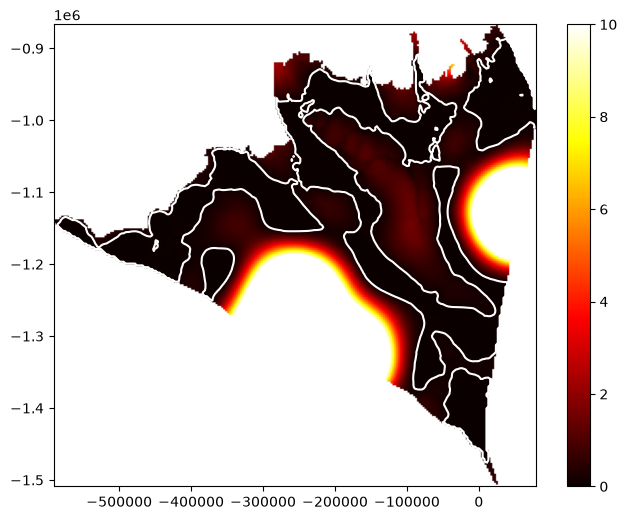

In [90]:
# MAP
map_z_gp = result.x
enthalpy_map = forward_model.enthalpy(map_z_gp)
physical_result_MAP = forward_model.physical_state(map_z_gp)

plt.figure(figsize=(8, 6))
plt.imshow(physical_result_MAP["delta_T"].reshape(sims.nx, sims.ny),
           cmap='hot',
           origin='lower',
           vmin=0, vmax=10,
           extent=sims.extent)
plt.colorbar()

# add a 0.5 contour
plt.contour(physical_result_MAP["delta_T"].reshape(sims.nx, sims.ny),
            levels=[0.1],
            colors='white',
            extent=sims.extent)
plt.show()


# Part 5: Solve for MAP and posterior distributions with mixture model

In [101]:
import torch
import scipy as sp
import itertools

from latentEnthalpyModel import latentEnthalpyModel, BasalEvidence, PosteriorConfig
from enthalpyPosterior import enthalpyPosterior

iteration_counter = itertools.count(1)

def print_progress(intermediate_result):
    iteration = next(iteration_counter)

    # SciPy supplies the current parameters and objective value.
    theta = intermediate_result.x
    value = intermediate_result.fun

    # Additional gradient evaluation for monitoring.
    gradient = np.asarray(objective.gradient(theta))
    grad_inf = np.max(np.abs(gradient))

    print(
        f"{iteration:4d} | "
        f"objective = {value: .8e} | "
        f"||grad||_inf = {grad_inf:.3e}",
        flush=True,
    )

gp_prior = lowRankGPPrior(
    domain_mask = sims.domain_mask,
    hx = sims.delta_x,
    hy = sims.delta_y,
    n_mode = 150,
    # pca_basis = sims.pca_x[0].components_.T, # only look at Eb
    pca_basis = null_basis, # only look at Eb
    sigma_amp = 200,
    nu = 1,
    rho = 1, # 1
)

forward_model = latentEnthalpyModel(
    pca = sims.pca_x[0],
    gp = gp_prior,
    scaler = sims.scaling_models[0],
    Tpmp = pmp,
)

posterior = enthalpyPosterior(
    forward_model = forward_model,
    evidence = evidence,
    gmm = sim_prior,
    gp  = gp_prior,
    config = config,
)

# initialize posterior guess
n_gmm_dim = sims.ndim_reduced[0]
n_gp_dim  = gp_prior.n_mode

objective = posteriorObjective(
    posterior = posterior,
)


theta0 = np.concatenate([
    torch.zeros(n_gp_dim),
    torch.zeros(n_gmm_dim)
])

print("Iter | Objective value | Gradient infinity norm")

result = sp.optimize.minimize(
    fun=objective.value,
    x0=theta0,
    jac=objective.gradient,
    method="L-BFGS-B",
    callback=print_progress,
    options={
        "maxiter": 200,
        "maxfun": 3000,
        "maxls": 30,
        "ftol": 1e-9,
        "gtol": 1e-6,
    },
)

Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.
Iter | Objective value | Gradient infinity norm
   1 | objective =  3.31091454e+03 | ||grad||_inf = 2.691e+01
   2 | objective =  3.29060358e+03 | ||grad||_inf = 1.492e+01
   3 | objective =  3.26823546e+03 | ||grad||_inf = 1.219e+01
   4 | objective =  3.24087338e+03 | ||grad||_inf = 1.280e+01
   5 | objective =  3.21102198e+03 | ||grad||_inf = 1.338e+01
   6 | objective =  3.19090592e+03 | ||grad||_inf = 1.905e+01
   7 | objective =  3.16545778e+03 | ||grad||_inf = 1.068e+01
   8 | objective =  3.14237851e+03 | ||grad||_inf = 4.241e+00
   9 | objective =  3.10254250e+03 | ||grad||_inf = 2.602e+00
  10 | objective =  3.09020164e+03 | ||grad||_inf = 7.700e+00
  11 | objective =  3.07543101e+03 | ||grad||_inf = 2.296e+00
  12 | objective =  3.06880199e+03 | ||grad||_inf = 1.807e+00
  13 | objective =  3.04765657e+03

### Posterior distribution via Laplace Approximation

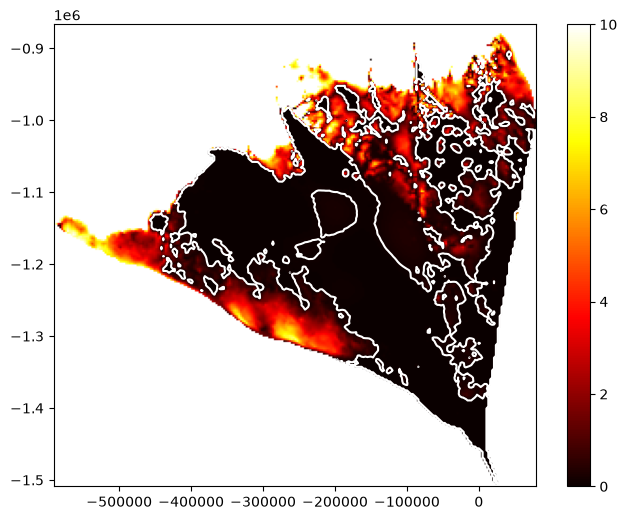

In [102]:
from utilities import robust_posterior_marginal_mapping

# MAP
map_z_gp = result.x[:n_gp_dim]
map_z_gmm = result.x[n_gp_dim:]
enthalpy_map = forward_model.enthalpy(map_z_gp, map_z_gmm)
physical_result_MAP = forward_model.physical_state(map_z_gp, map_z_gmm)

plt.figure(figsize=(8, 6))
plt.imshow(physical_result_MAP["delta_T"].reshape(sims.nx, sims.ny), 
           cmap='hot',
           origin='lower',
           vmin=0, vmax=10,
           extent=sims.extent)
plt.colorbar()

# add a 0.5 contour
plt.contour(physical_result_MAP["delta_T"].reshape(sims.nx, sims.ny),
            levels=[0.1],
            colors='white',
            extent=sims.extent)
plt.show()


Processed 0 / 1000 samples.
Processed 100 / 1000 samples.
Processed 200 / 1000 samples.
Processed 300 / 1000 samples.
Processed 400 / 1000 samples.
Processed 500 / 1000 samples.
Processed 600 / 1000 samples.
Processed 700 / 1000 samples.
Processed 800 / 1000 samples.
Processed 900 / 1000 samples.


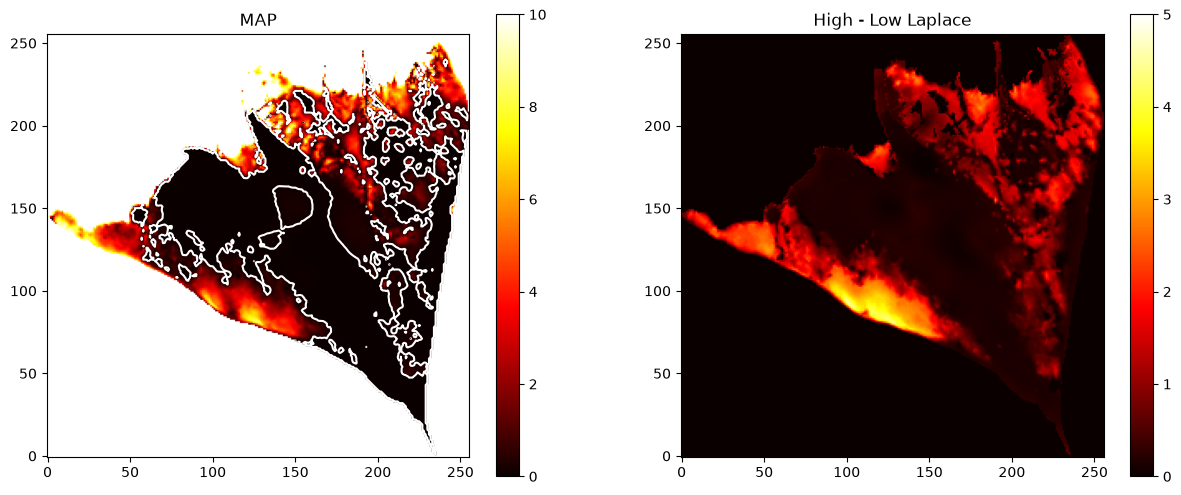

In [103]:
# Laplace approximation: compute the negative inverse of the Hessian at the MAP estimate
laplace_samples = posterior.laplace_approx(
    map_z_gp, 
    map_z_gmm, 
    n_sample=1000
)

laplace_z_gp  = laplace_samples[:, posterior.gp_dim_index]
laplace_z_gmm = laplace_samples[:, posterior.gmm_dim_index]

def forward_to_dT(sample):
    z_gp = sample[posterior.gp_dim_index]
    z_gmm = sample[posterior.gmm_dim_index]
    results = forward_model.physical_state(z_gp, z_gmm)
    return results["delta_T"]

low_laplace, mean_laplace, high_laplace = robust_posterior_marginal_mapping(
    forward_to_dT,
    laplace_samples,
    temp_path="../data/posterior-laplace/",
    n_intermediate=500,
    memory_budget_mb=4096,
)


plt.figure(figsize=(15, 6))
plt.subplot(1,2,1)
plt.imshow(physical_result_MAP["delta_T"].reshape(sims.nx, sims.ny),
           cmap='hot',
           vmin=0, vmax=10)
plt.colorbar()
# add a 0.5 contour
plt.contour(physical_result_MAP["delta_T"].reshape(sims.nx, sims.ny),
            levels=[0.1],
            colors='white')
plt.title("MAP")
plt.gca().invert_yaxis()

plt.subplot(1,2,2)
plt.imshow(high_laplace.reshape(sims.nx, sims.ny) - low_laplace.reshape(sims.nx, sims.ny),
           cmap='hot',
           vmin=0, vmax=5)
plt.title("High - Low Laplace")
plt.gca().invert_yaxis()
plt.colorbar()

plt.show()

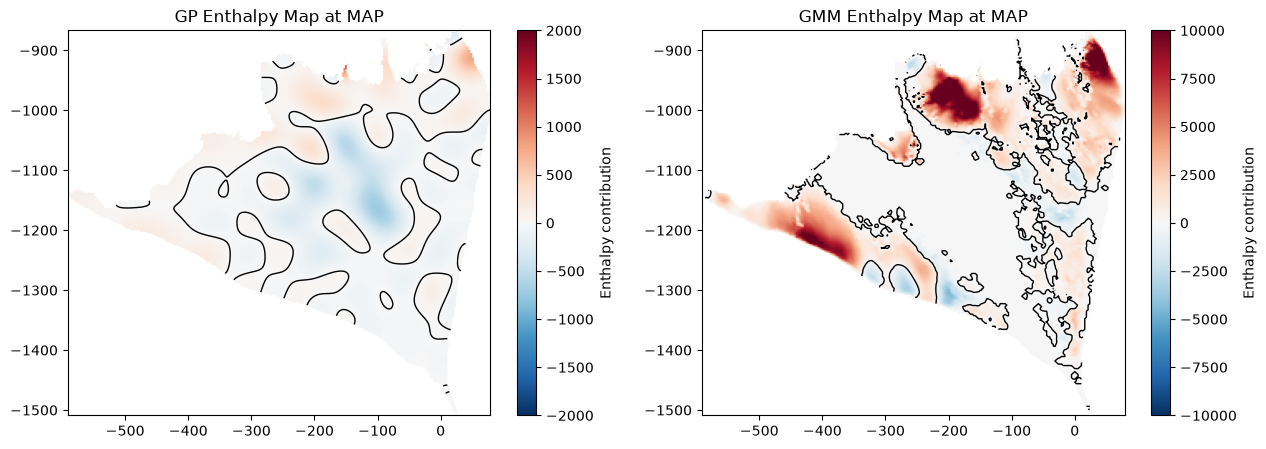

In [105]:
# plot the separate contributions
map_z_gp  = map_z_gp.reshape(map_z_gp.shape[0], -1)
map_z_gmm = map_z_gmm.reshape(map_z_gmm.shape[0], -1)
enthalpy_map_gp = forward_model.decode_gp(map_z_gp)
enthalpy_map_gmm = forward_model.decode_gmm(map_z_gmm)
# reverse standardize
enthalpy_map_gmm = sims.scaling_models[0].inverse_transform(enthalpy_map_gmm.T) - sims.scaling_models[0].mean_

enthalpy_map_gp = np.where(
    sims.domain_mask.flatten(), 
    enthalpy_map_gp.flatten(), 
    np.nan
)
enthalpy_map_gmm = np.where(
    sims.domain_mask.flatten(), 
    enthalpy_map_gmm.flatten(), 
    np.nan
)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.imshow(enthalpy_map_gp.reshape(sims.nx, sims.ny), 
           aspect='auto',
           cmap='RdBu_r',
           origin='lower',
           vmin=-2e3, vmax=2e3,
           extent=extent_km)
# colorbar with label
plt.colorbar(label='Enthalpy contribution')
# add a zero contour
plt.contour(enthalpy_map_gp.reshape(sims.nx, sims.ny), 
            levels=[0], 
            colors='k', 
            linewidths=1,
            extent=extent_km)
plt.title('GP Enthalpy Map at MAP')


plt.subplot(1, 2, 2)
plt.imshow(enthalpy_map_gmm.reshape(sims.nx, sims.ny), 
           aspect='auto',
           cmap='RdBu_r',
           origin='lower',
           vmin=-1e4, vmax=1e4,
           extent=extent_km)
plt.colorbar(label='Enthalpy contribution')  
plt.contour(enthalpy_map_gmm.reshape(sims.nx, sims.ny), 
            levels=[0], 
            colors='k', 
            linewidths=1,
            extent=extent_km)
plt.title('GMM Enthalpy Map at MAP')
plt.show()

### Posterior distribution via Hamiltonian Monte Carlo

In [59]:
from hamiltonianMonteCarlo import HMCenergy, RegularPotential
import pyro.infer.mcmc as mcmc
from pyro.ops.stats import effective_sample_size

# posterior.config.beta = 1
potential = RegularPotential(posterior)
print(f"beta is set at {potential.posterior.config.beta}")
# initialize target parameters
z_gp_init  = torch.tensor(map_z_gp, dtype=torch.float64)
z_gmm_init = torch.tensor(map_z_gmm, dtype=torch.float64)

# specify NUTS kernel
nuts_kernel = mcmc.NUTS(
    potential_fn = potential,
    adapt_step_size=True,
    adapt_mass_matrix=True,
    full_mass=False,
    max_tree_depth=7,
    target_accept_prob=0.8
)
# specify MCMC run
mcmc_run = mcmc.MCMC(
    nuts_kernel,
    num_samples=3000,
    warmup_steps=500,
    initial_params={"z_gp": z_gp_init, "z_gmm": z_gmm_init},
)
mcmc_run.run()

# statistics
samples = mcmc_run.get_samples(group_by_chain=True)

ess_gp = effective_sample_size(
    samples["z_gp"],
    chain_dim=0,
    sample_dim=1,
)

ess_gmm = effective_sample_size(
    samples["z_gmm"],
    chain_dim=0,
    sample_dim=1,
)

print("Minimum GP ESS:", ess_gp.min().item())
print("Median GP ESS:", ess_gp.median().item())
print("Max GP ESS:", ess_gp.max().item())

print("Minimum GMM ESS:", ess_gmm.min().item())
print("Median GMM ESS:", ess_gmm.median().item())
print("Max GMM ESS:", ess_gmm.max().item())



beta is set at 0.5


Warmup:   1%|          | 23/3500 [14:54, 41.65s/it, step size=9.36e-02, acc. prob=0.751]

KeyboardInterrupt: 

In [ ]:
import numpy as np
from utilities import robust_posterior_marginal_mapping

def forward_to_dT(sample):
    z_gp = sample[:n_gp_dim]
    z_gmm = sample[n_gp_dim:]
    results = forward_model.physical_state(z_gp, z_gmm)
    return results["delta_T"]

gp_samples  = samples["z_gp"].cpu()  # (num_samples, D)
gmm_samples = samples["z_gmm"].cpu()  # (num_samples, D)
gp_new_shape   = gp_samples.shape[1:3]
gmm_new_shape  = gmm_samples.shape[1:3]
gp_samples  = gp_samples.reshape(gp_samples.shape[0], -1)
gmm_samples = gmm_samples.reshape(gmm_samples.shape[0], -1)

n_gp_dim = gp_samples.shape[1]
n_gmm_dim = gmm_samples.shape[1]
joint_samples = np.hstack([gp_samples, gmm_samples])

hmc_low, hmc_mean, hmc_high = robust_posterior_marginal_mapping(
    forward_to_dT,
    joint_samples,
)

In [ ]:
cb_upper = 15

plt.figure(figsize=(20,5))
plt.subplot(1,3,1)
plt.imshow(hmc_low.reshape(sims.nx, sims.ny), 
           cmap='hot',
           vmin=0,vmax=cb_upper)
plt.colorbar()
plt.gca().invert_yaxis()

plt.subplot(1,3,2)
plt.imshow(hmc_mean.reshape(sims.nx, sims.ny), 
           cmap='hot',
           vmin=0,vmax=cb_upper)
plt.colorbar()
plt.gca().invert_yaxis()

plt.subplot(1,3,3)
plt.imshow(hmc_high.reshape(sims.nx, sims.ny), 
           cmap='hot',
           vmin=0,vmax=cb_upper)
plt.colorbar()
plt.gca().invert_yaxis()
plt.show()

# make another plot just showing the interquantile range
plt.figure(figsize=(10,5))
plt.plot(sims.domain_bound_line[0], sims.domain_bound_line[1],'white')
plt.imshow((hmc_high - hmc_low).reshape(sims.nx, sims.ny), 
           cmap='hot',
           vmin=0,vmax=5,
           extent=sims.extent)
plt.colorbar()
plt.gca().invert_yaxis()
plt.show()